# 08 - PCA sweep

Mirrors `notebooks_withseed/07_pca_curve`. Sweeps the number of PCA components from 1 to 50 for
each classifier, showing how sensitive results are to dimensionality.

Read the peaks cautiously: the maximum of a noisy 50-point sweep is optimistically biased, so treat
this as diagnostic rather than a source of headline numbers.

In [4]:
import os, sys, json
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
import warnings; warnings.filterwarnings('ignore')
import numpy as np, torch
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
OSF, OUT = '../data/preprocessed', '../results_parcel'
MODEL, SUFFIX = 'tiny', 'cortical'
cv = StratifiedKFold(5, shuffle=True, random_state=123)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import RidgeClassifier

labels = np.load(f'{OUT}/parcel_labels_{SUFFIX}.npy')
X = np.load(f'{OUT}/parcel_frozen_{MODEL}_{SUFFIX}.npy')
S, PCA_MAX = 123, 50
comps = list(range(1, min(PCA_MAX, X.shape[1]) + 1))
print(f'{X.shape} | sweeping PCA 1..{comps[-1]}')

SPEC = [
 ('LR L2',        LogisticRegression(max_iter=2000), False),
 ('Ridge',        RidgeClassifier(), True),
 ('Linear SVM',   LinearSVC(max_iter=5000, random_state=S), True),
 ('RBF SVM',      SVC(kernel='rbf', random_state=S), True),
 ('kNN k=5',      KNeighborsClassifier(n_neighbors=5), True),
 ('LDA (shrink)', LinearDiscriminantAnalysis(solver='lsqr', shrinkage='auto'), True),
 ('RandomForest', RandomForestClassifier(n_estimators=150, random_state=S, n_jobs=-1), False),
 ('ExtraTrees',   ExtraTreesClassifier(n_estimators=150, random_state=S, n_jobs=-1), False),
 ('HistGradBoost',HistGradientBoostingClassifier(random_state=S), False),
 ('MLP (64)',     MLPClassifier(hidden_layer_sizes=(64,), max_iter=1000, random_state=S), True),
]

(161, 4096) | sweeping PCA 1..50


In [5]:
from sklearn.model_selection import cross_val_score
curves = {}
for name, clf, scale in SPEC:
    accs = []
    for n in comps:
        steps = [PCA(n_components=n, random_state=S)]
        if scale: steps.append(StandardScaler())
        steps.append(clf)
        accs.append(cross_val_score(make_pipeline(*steps), X, labels, cv=cv, scoring='accuracy').mean())
    curves[name] = np.array(accs)
    i = int(np.argmax(accs))
    print(f'  {name:15s} peak {accs[i]:.3f} @ PCA-{comps[i]}', flush=True)

  LR L2           peak 0.857 @ PCA-5
  Ridge           peak 0.875 @ PCA-27
  Linear SVM      peak 0.856 @ PCA-13
  RBF SVM         peak 0.882 @ PCA-21
  kNN k=5         peak 0.844 @ PCA-2
  LDA (shrink)    peak 0.888 @ PCA-20
  RandomForest    peak 0.863 @ PCA-14
  ExtraTrees      peak 0.894 @ PCA-14
  HistGradBoost   peak 0.857 @ PCA-5
  MLP (64)        peak 0.876 @ PCA-25


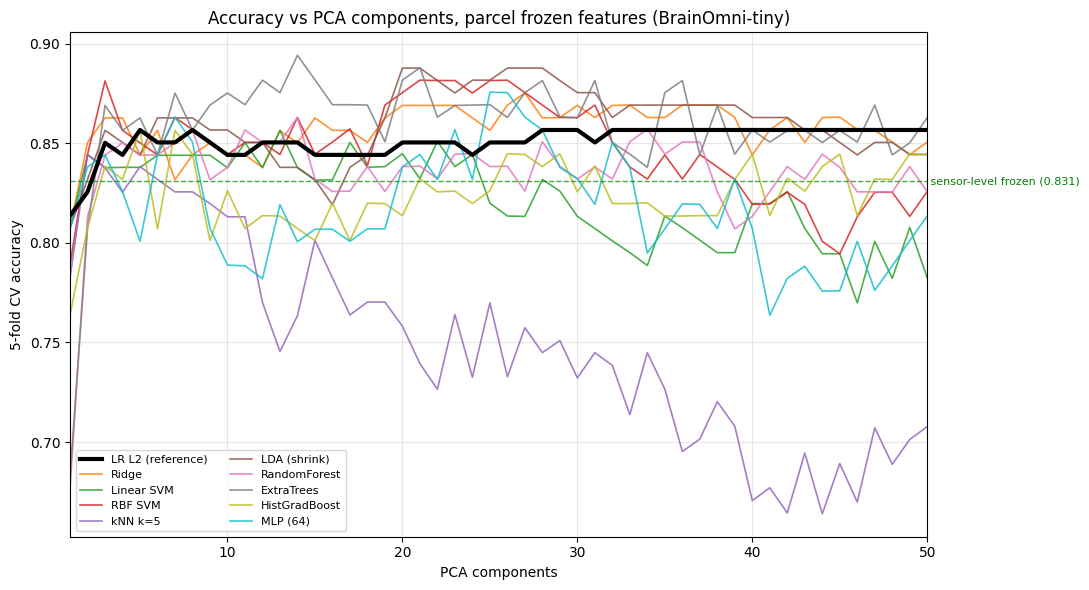

saved parcel_pca_curve.png


In [6]:
fig, ax = plt.subplots(figsize=(11, 6))
cmap = plt.get_cmap('tab10')
for i, (name, acc) in enumerate(curves.items()):
    if name == 'LR L2': ax.plot(comps, acc, color='black', lw=3, zorder=10, label='LR L2 (reference)')
    else:               ax.plot(comps, acc, color=cmap(i % 10), lw=1.2, alpha=0.85, label=name)
ax.axhline(0.831, color='green', ls='--', lw=1, alpha=0.7)
ax.text(comps[-1], 0.831, ' sensor-level frozen (0.831)', color='green', va='center', fontsize=8)
ax.set_xlabel('PCA components'); ax.set_ylabel('5-fold CV accuracy')
ax.set_title(f'Accuracy vs PCA components, parcel frozen features (BrainOmni-{MODEL})')
ax.set_xlim(1, comps[-1]); ax.grid(alpha=0.3); ax.set_axisbelow(True); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(f'{OUT}/parcel_pca_curve_{MODEL}.png', dpi=150); plt.show()
print('saved parcel_pca_curve.png')